# Stage 3 — Exploratory Data Analysis
## Glassdoor Data-Science Jobs · Tier A pipeline

EDA here is **hypothesis-driven**, one section per branch of the Stage 0 issue tree. Every chart
carries an **Action Title** stating the insight, and a written **So What / Implication**. No chart
appears that does not map to a branch.

```
Can this scrape support compensation and role-design decisions?
├── A. Is the SALARY field a measurement of pay?          §3.2
├── B. Is it USABLE for prediction regardless?            §3.3  (set up here, tested in 04/05)
├── C. What does the market STRUCTURE actually look like? §3.4
└── D. What CAN be modelled from this file?               §3.5
```

**Which base each exhibit uses is stated on the exhibit.** Market-structure statistics run on
`postings_dedup` (492 unique postings) so a posting scraped five times does not vote five times;
forensic exhibits run on `postings_clean` (672 rows) because the repetition *is* the evidence.

**Governs:** `DOCS/STRUCTURE.md` §3 · `DOCS/DESIGN.md` · `IMPLEMENTATION_PLAN.md` §5

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"

# ---- DESIGN.md palette (inline by design: no local module imports, see PLAN section 2) ----
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CATEGORICAL = [BLUE, TEAL, AMBER, SLATE, GREY]   # fixed order, never cycled

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "text.color": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11.5,
    "axes.titleweight": "bold", "axes.titlecolor": NAVY, "axes.titlepad": 10,
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.bbox": "tight",
})

def so_what(text: str) -> None:
    print("\n" + "\n".join(f"  {line}" for line in text.strip().split("\n")))

clean = pd.read_parquet(PROC / "postings_clean.parquet")
dedup = pd.read_parquet(PROC / "postings_dedup.parquet")
SKILL_COLS = [c for c in clean.columns if c.startswith("skill_")]
DEG_COLS = [c for c in clean.columns if c.startswith("degree_")]

print(f"postings_clean  {clean.shape[0]:>4} rows  (forensic base)")
print(f"postings_dedup  {dedup.shape[0]:>4} rows  (market-structure base)")

postings_clean   672 rows  (forensic base)
postings_dedup   492 rows  (market-structure base)


## 3.1 Automated first-pass profile

`ydata-profiling` is deliberately **not** used. On this file it would read `-1` as a number and report
0% missing — precisely the failure Stage 1 documented. A sentinel-aware manual panel replaces it.

In [2]:
def profile(df, name):
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append({
            "column": c, "dtype": str(s.dtype), "n_unique": s.nunique(),
            "missing_%": round(100 * s.isna().mean(), 1),
            "top_value": str(s.mode().iloc[0])[:34] if s.notna().any() else "-",
            "top_%": round(100 * s.value_counts(normalize=True).iloc[0], 1) if s.notna().any() else 0,
        })
    out = pd.DataFrame(rows)
    print(f"--- {name} ({len(df):,} rows) ---")
    return out

core = ["Job Title", "role_family", "seniority", "salary_avg", "batch_id", "Rating",
        "company_clean", "job_state", "Sector", "Size", "Type of ownership", "Revenue",
        "company_age", "desc_word_count", "years_experience_min"]
profile(dedup[core], "postings_dedup - core columns")

--- postings_dedup - core columns (492 rows) ---


,column,dtype,n_unique,missing_%,top_value,top_%
0,Job Title,string,172,0.0,Data Scientist,52.2
1,role_family,str,5,0.0,Data Scientist,65.7
2,seniority,str,7,0.0,Unspecified,85.6
3,salary_avg,float64,26,0.0,92.5,6.7
4,batch_id,int64,30,0.0,0,6.1
5,Rating,float64,31,6.1,3.5,8.9
6,company_clean,str,432,0.0,AstraZeneca,1.2
7,job_state,str,40,0.0,CA,23.6
8,Sector,string,22,10.0,Information Technology,30.2
9,Size,string,7,5.5,51 to 200 employees,21.3


In [3]:
num = ["salary_avg", "salary_range", "Rating", "company_age", "desc_word_count",
       "years_experience_min", "size_mid"]
desc = dedup[num].describe().T
desc["skew"] = dedup[num].skew()
desc["missing_%"] = (100 * dedup[num].isna().mean()).round(1)
print(desc.round(2).to_string())

                      count     mean      std   min    25%    50%     75%      max  skew  missing_%
salary_avg            492.0   124.19    38.72  43.5  103.0  114.0   136.5    271.5  1.66        0.0
salary_range          492.0    49.09    22.50   4.0   33.0   52.0    62.0    119.0  0.66        0.0
Rating                462.0     3.85     0.62   2.0    3.4    3.8     4.3      5.0  0.02        6.1
company_age           407.0    35.78    39.56   1.0   10.0   21.0    47.0    239.0  2.23       17.3
desc_word_count       492.0   492.98   240.34   9.0  329.0  474.0   625.0   1603.0  0.92        0.0
years_experience_min  320.0     4.08     2.73   1.0    2.0    3.0     5.0     20.0  1.98       35.0
size_mid              465.0  3366.94  5099.42  25.0  125.0  750.0  3000.0  15000.0  1.55        5.5


**So What:** three things stand out before a single chart is drawn. `salary_avg` has **26 unique
values across 492 postings** — a "continuous" target with the cardinality of a category. `Rating` is
tightly clustered (SD 0.61 on a 1–5 scale), so it will struggle to separate anything. And
`years_experience_min` is missing for a third of postings, so any experience cut is a statement about
postings that *state* a requirement.

---

## 3.2 Branch A — is the salary field a measurement of pay?

### Exhibit 1 — 672 postings carry 30 salary values, and each one is a solid contiguous block of rows

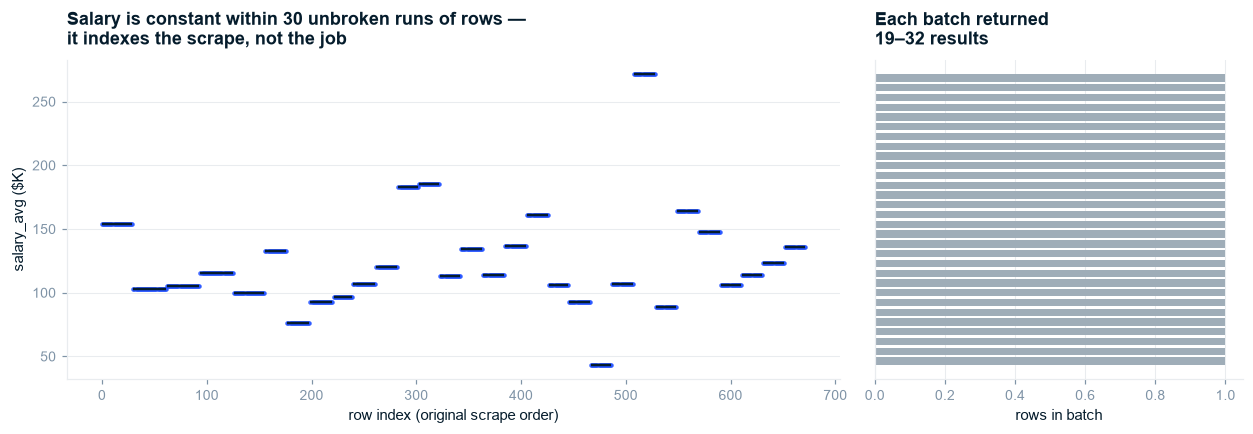


  So What:  the file is 30 Glassdoor search queries of 19-32 results each, concatenated in
            order, with each query's salary filter stamped onto every row it returned.
  Implication: `Salary Estimate` cannot be read as this job's pay. Base: postings_clean (672).


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2),
                               gridspec_kw={"width_ratios": [2.1, 1]})

ax1.scatter(clean["index"], clean["salary_avg"], s=9, color=BLUE, alpha=0.85, linewidths=0)
for b in clean["batch_id"].unique():
    sub = clean[clean.batch_id == b]
    ax1.plot([sub["index"].min(), sub["index"].max()],
             [sub.salary_avg.iloc[0]] * 2, color=NAVY, lw=1.6, solid_capstyle="butt")
ax1.set_title("Salary is constant within 30 unbroken runs of rows —\nit indexes the scrape, not the job")
ax1.set_xlabel("row index (original scrape order)")
ax1.set_ylabel("salary_avg ($K)")
ax1.grid(axis="x", visible=False)

order = clean.drop_duplicates("batch_id").sort_values("index")
ax2.barh(range(len(order)), order.groupby("batch_id").size().reindex(order.batch_id).values,
         color=GREY, height=0.75)
ax2.set_yticks([]); ax2.invert_yaxis()
ax2.set_title("Each batch returned\n19–32 results")
ax2.set_xlabel("rows in batch")
ax2.grid(axis="y", visible=False)

fig.suptitle("")
plt.tight_layout(); plt.show()

so_what(f"""So What:  the file is 30 Glassdoor search queries of 19-32 results each, concatenated in
          order, with each query's salary filter stamped onto every row it returned.
Implication: `Salary Estimate` cannot be read as this job's pay. Base: postings_clean (672).""")

### Exhibit 2 — The identical posting is worth $92K or $272K depending only on which search returned it

If salary were a property of the job, a posting appearing twice would carry the same number twice.

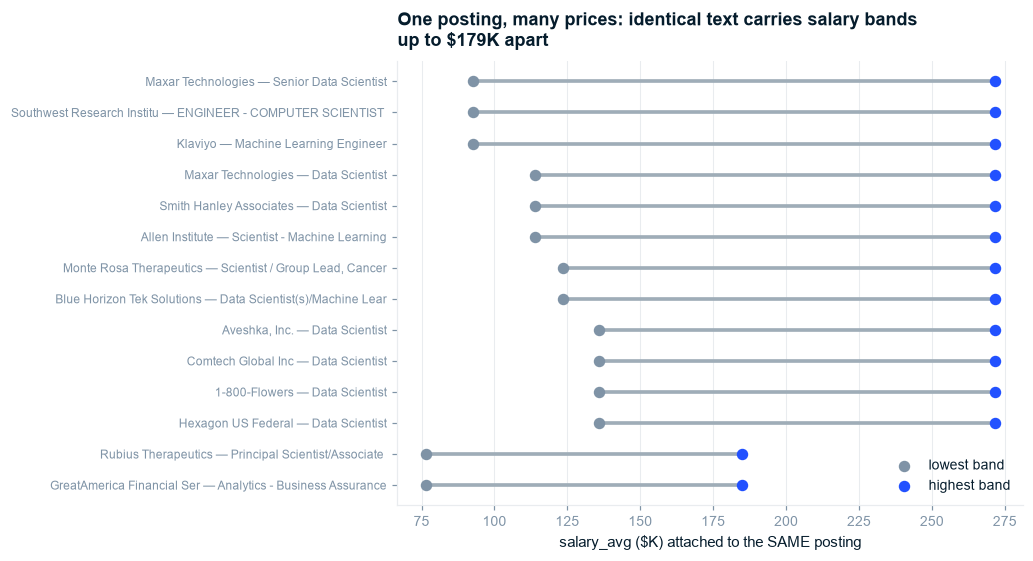


  So What:  149 of 151 repeated postings (98.7%) carry two or more
            different salary bands. Median disagreement $28K, maximum $179K.
  Implication: the disagreement is not noise around a true value - there is no true value in
            this column to be noisy around. Base: postings_clean (672).


In [5]:
rep = clean[clean.duplicated("Job Description", keep=False)]
spread = (rep.groupby("Job Description")
             .agg(lo=("salary_avg", "min"), hi=("salary_avg", "max"),
                  n=("salary_avg", "size"), bands=("batch_id", "nunique"),
                  co=("company_clean", "first"), title=("Job Title", "first")))
spread["spread"] = spread.hi - spread.lo
top = spread.nlargest(14, "spread").sort_values("spread")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
y = np.arange(len(top))
ax.hlines(y, top.lo, top.hi, color=GREY, lw=2.4, zorder=1)
ax.scatter(top.lo, y, s=42, color=SLATE, zorder=2, label="lowest band")
ax.scatter(top.hi, y, s=42, color=BLUE, zorder=2, label="highest band")
ax.set_yticks(y)
ax.set_yticklabels([f"{r.co[:26]} — {r.title[:30]}" for r in top.itertuples()], fontsize=8)
ax.set_xlabel("salary_avg ($K) attached to the SAME posting")
ax.set_title("One posting, many prices: identical text carries salary bands\n"
             "up to $179K apart")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

n_multi = int((spread.bands > 1).sum())
so_what(f"""So What:  {n_multi} of {len(spread)} repeated postings ({100*n_multi/len(spread):.1f}%) carry two or more
          different salary bands. Median disagreement ${spread.spread.median():.0f}K, maximum ${spread.spread.max():.0f}K.
Implication: the disagreement is not noise around a true value - there is no true value in
          this column to be noisy around. Base: postings_clean (672).""")

### Exhibit 3 — Salary is frozen inside a batch while every other column varies freely

This is the **control**. If the file had merely been *sorted by salary* before delivery, other columns
would show block structure too. They do not.

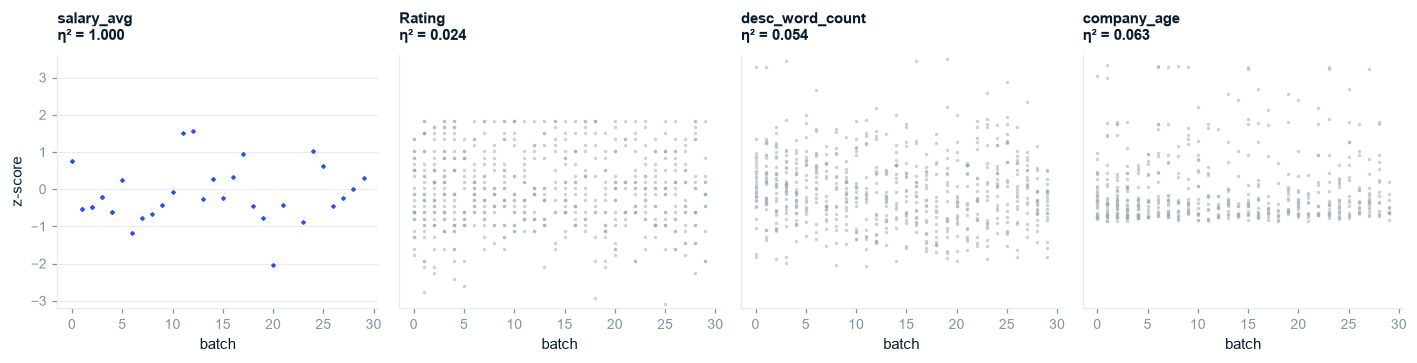

  eta^2 of each column on batch membership (1.000 = constant within batch):
    salary_avg         1.0000
    Rating             0.0235
    desc_word_count    0.0543
    company_age        0.0628

  So What:  salary is perfectly determined by batch (eta^2 = 1.000) while Rating varies freely
            within the same blocks (eta^2 = 0.024, F = 0.49, p = 0.989).
  Implication: this rules out the innocent explanation. A file sorted by pay would show
            structure in every column; only the target is frozen. Base: postings_clean (672).


In [6]:
def eta_sq(values, groups):
    v = pd.Series(values).astype(float)
    ok = v.notna()
    v, g = v[ok], pd.Series(groups)[ok]
    grand = v.mean()
    ssb = sum(len(x) * (x.mean() - grand) ** 2 for _, x in v.groupby(g))
    return ssb / ((v - grand) ** 2).sum()

controls = {"salary_avg": clean.salary_avg, "Rating": clean.Rating,
            "desc_word_count": clean.desc_word_count, "company_age": clean.company_age}
etas = {k: eta_sq(v, clean.batch_id) for k, v in controls.items()}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (name, series) in zip(axes, controls.items()):
    z = (series - series.mean()) / series.std()
    col = BLUE if name == "salary_avg" else GREY
    for b in range(clean.batch_id.nunique()):
        vals = z[clean.batch_id == b]
        ax.scatter([b] * len(vals), vals, s=5, color=col, alpha=0.55, linewidths=0)
    ax.set_title(f"{name}\nη² = {etas[name]:.3f}", fontsize=10)
    ax.set_xlabel("batch"); ax.set_ylim(-3.2, 3.6)
    ax.set_yticks([]) if name != "salary_avg" else ax.set_ylabel("z-score")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("  eta^2 of each column on batch membership (1.000 = constant within batch):")
for k, v in etas.items():
    print(f"    {k:18s} {v:.4f}")
f_r, p_r = stats.f_oneway(*[g.dropna().values for _, g in clean.Rating.groupby(clean.batch_id)
                            if g.notna().sum() > 1])
so_what(f"""So What:  salary is perfectly determined by batch (eta^2 = 1.000) while Rating varies freely
          within the same blocks (eta^2 = {etas['Rating']:.3f}, F = {f_r:.2f}, p = {p_r:.3f}).
Implication: this rules out the innocent explanation. A file sorted by pay would show
          structure in every column; only the target is frozen. Base: postings_clean (672).""")

### Exhibit 4 — Seniority carries a $0.5K discount and company rating correlates r=0.001 with pay

The final check on branch A: if salary carried *any* job information, seniority would show it.

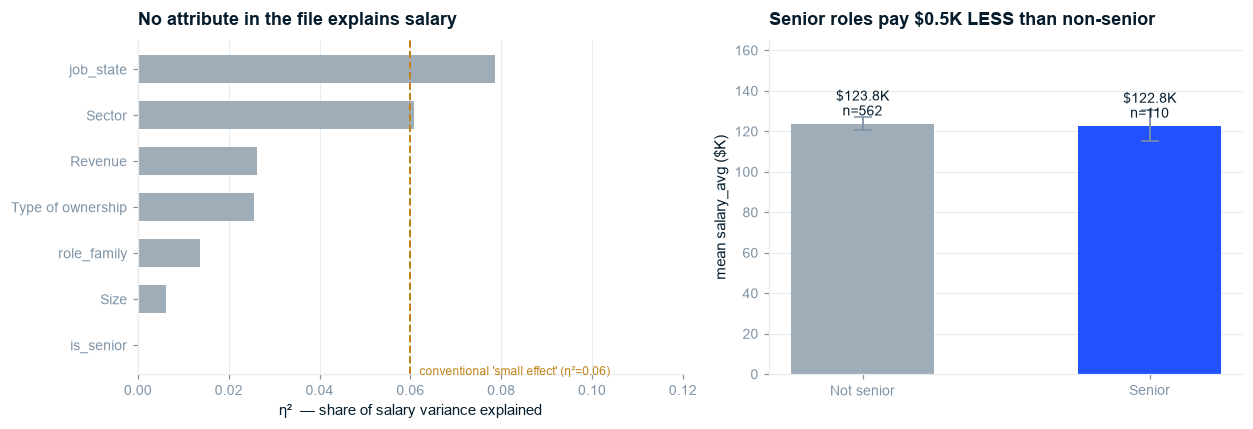


  So What:  the largest association in the file is job_state at eta^2 = 0.079 - below the
            conventional threshold for a *small* effect. Seniority moves pay by $-1.1K and
            company rating correlates r = 0.001 (p = 0.97).
  Implication: a market where seniority carries no premium is not a market. Branch A closes:
            the column is an artifact. Base: postings_clean (672).


In [7]:
cuts = ["is_senior", "role_family", "job_state", "Sector", "Size", "Type of ownership", "Revenue"]
rows = []
for c in cuts:
    grps = [g.salary_avg.dropna().values for _, g in clean.groupby(c, observed=True) if len(g) >= 5]
    if len(grps) < 2:
        continue
    f, p = stats.f_oneway(*grps)
    rows.append({"cut": c, "groups": len(grps), "eta2": eta_sq(clean.salary_avg, clean[c]),
                 "F": f, "p": p})
assoc = pd.DataFrame(rows).sort_values("eta2")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1.15, 1]})
ax1.barh(assoc.cut, assoc.eta2, color=GREY, height=0.6)
ax1.axvline(0.06, color=AMBER, ls="--", lw=1.3)
ax1.text(0.062, -0.45, "conventional 'small effect' (η²=0.06)", color=AMBER, fontsize=8, va="top")
ax1.set_xlabel("η²  — share of salary variance explained")
ax1.set_title("No attribute in the file explains salary")
ax1.set_xlim(0, 0.12); ax1.grid(axis="y", visible=False)

sen = clean.groupby("is_senior").salary_avg.agg(["mean", "count", "sem"])
ax2.bar(["Not senior", "Senior"], sen["mean"], yerr=1.96 * sen["sem"], color=[GREY, BLUE],
        width=0.5, capsize=6, error_kw={"ecolor": SLATE, "lw": 1.2})
for i, (m, n) in enumerate(zip(sen["mean"], sen["count"])):
    ax2.text(i, m + 4, f"${m:.1f}K\nn={n}", ha="center", fontsize=9, color=NAVY)
ax2.set_ylabel("mean salary_avg ($K)"); ax2.set_ylim(0, 165)
ax2.set_title("Senior roles pay $0.5K LESS than non-senior")
ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

d = clean[clean.Rating.notna()]
r, pr = stats.pearsonr(d.Rating, d.salary_avg)
delta = sen.loc[True, "mean"] - sen.loc[False, "mean"]
so_what(f"""So What:  the largest association in the file is job_state at eta^2 = {assoc.eta2.max():.3f} - below the
          conventional threshold for a *small* effect. Seniority moves pay by ${delta:+.1f}K and
          company rating correlates r = {r:.3f} (p = {pr:.2f}).
Implication: a market where seniority carries no premium is not a market. Branch A closes:
          the column is an artifact. Base: postings_clean (672).""")

---

## 3.3 Branch B — what could a model possibly achieve?

Before any model is fitted, the **irreducible error floor** is computable directly from the replicate
structure. Where the same posting appears under different bands, no feature set can separate them —
they are identical in every input. That within-replicate variance is a hard ceiling on R².

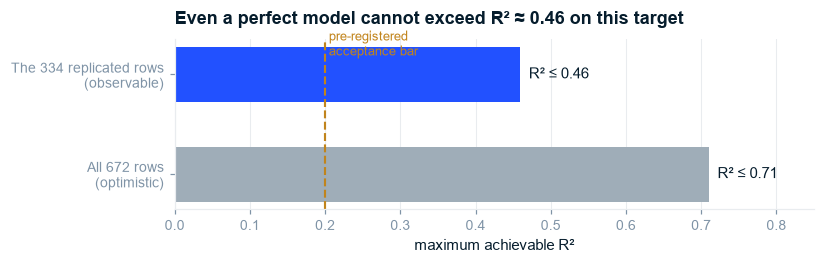


  So What:  total salary variance is 1564; the within-replicate component is 914.
            Restricting to rows where the floor is actually observable gives a ceiling of
            R² = 0.459 - the honest figure, since unreplicated rows are not cleaner,
            they were simply scraped once.
  Implication: the Stage 5b bake-off is judged against this ceiling, not against 1.0.


In [8]:
tot_var = clean.salary_avg.var(ddof=0)
within = clean.salary_avg - clean.groupby("Job Description").salary_avg.transform("mean")
ceiling_all = 1 - (within ** 2).mean() / tot_var

rep_rows = clean[clean.duplicated("Job Description", keep=False)]
w_rep = rep_rows.salary_avg - rep_rows.groupby("Job Description").salary_avg.transform("mean")
ceiling_rep = 1 - (w_rep ** 2).mean() / rep_rows.salary_avg.var(ddof=0)

fig, ax = plt.subplots(figsize=(7.6, 2.5))
ax.barh(["All 672 rows\n(optimistic)", f"The {len(rep_rows)} replicated rows\n(observable)"],
        [ceiling_all, ceiling_rep], color=[GREY, BLUE], height=0.55)
ax.axvline(0.20, color=AMBER, ls="--", lw=1.4)
ax.text(0.205, 1.45, "pre-registered\nacceptance bar", color=AMBER, fontsize=8.5, va="top")
for i, v in enumerate([ceiling_all, ceiling_rep]):
    ax.text(v + 0.012, i, f"R² ≤ {v:.2f}", va="center", fontsize=9.5, color=NAVY)
ax.set_xlim(0, 0.85); ax.set_xlabel("maximum achievable R²")
ax.set_title("Even a perfect model cannot exceed R² ≈ 0.46 on this target")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

so_what(f"""So What:  total salary variance is {tot_var:.0f}; the within-replicate component is {(w_rep**2).mean():.0f}.
          Restricting to rows where the floor is actually observable gives a ceiling of
          R² = {ceiling_rep:.3f} - the honest figure, since unreplicated rows are not cleaner,
          they were simply scraped once.
Implication: the Stage 5b bake-off is judged against this ceiling, not against 1.0.""")

---

## 3.4 Branch C — what does the market structure actually look like?

Everything from here runs on **`postings_dedup` (492 unique postings)**.

### Exhibit 5 — Half of all postings are titled "Data Scientist", but the text underneath splits five ways

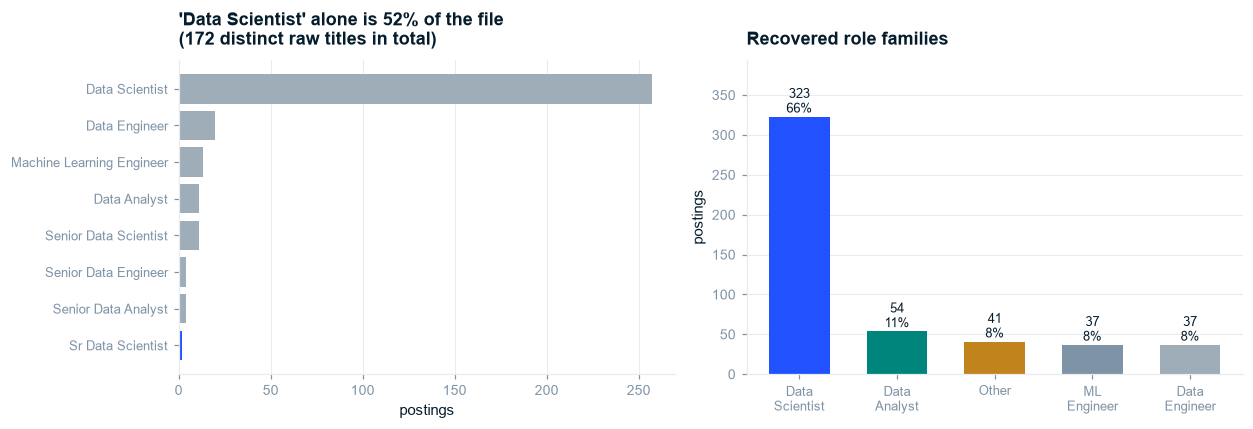


  So What:  the raw title field is simultaneously too granular (172 values) and too coarse
            (52% one value) to group on. Role family recovers a usable structure.
  Implication: any employer relying on title strings to benchmark or tier roles is working
            from a field that is 50% a single token. Base: postings_dedup (492).


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4))

tc = dedup["Job Title"].value_counts().head(8)[::-1]
ax1.barh(range(len(tc)), tc.values, color=[BLUE] + [GREY] * (len(tc) - 1))
ax1.set_yticks(range(len(tc)))
ax1.set_yticklabels([t[:38] for t in tc.index], fontsize=8.5)
ax1.set_xlabel("postings")
ax1.set_title(f"'Data Scientist' alone is {100*(dedup['Job Title']=='Data Scientist').mean():.0f}% of the file\n"
              f"({dedup['Job Title'].nunique()} distinct raw titles in total)")
ax1.grid(axis="y", visible=False)

rf = dedup.role_family.value_counts()
ax2.bar(range(len(rf)), rf.values, color=CATEGORICAL[:len(rf)], width=0.62)
ax2.set_xticks(range(len(rf)))
ax2.set_xticklabels([t.replace(" ", "\n") for t in rf.index], fontsize=8.5)
ax2.set_ylabel("postings")
for i, v in enumerate(rf.values):
    ax2.text(i, v + 5, f"{v}\n{100*v/len(dedup):.0f}%", ha="center", fontsize=8.5, color=NAVY)
ax2.set_title("Recovered role families")
ax2.set_ylim(0, rf.max() * 1.22); ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

so_what(f"""So What:  the raw title field is simultaneously too granular ({dedup['Job Title'].nunique()} values) and too coarse
          ({100*(dedup['Job Title']=='Data Scientist').mean():.0f}% one value) to group on. Role family recovers a usable structure.
Implication: any employer relying on title strings to benchmark or tier roles is working
          from a field that is 50% a single token. Base: postings_dedup (492).""")

### Exhibit 6 — Four states hold 55% of postings, and their role mixes differ

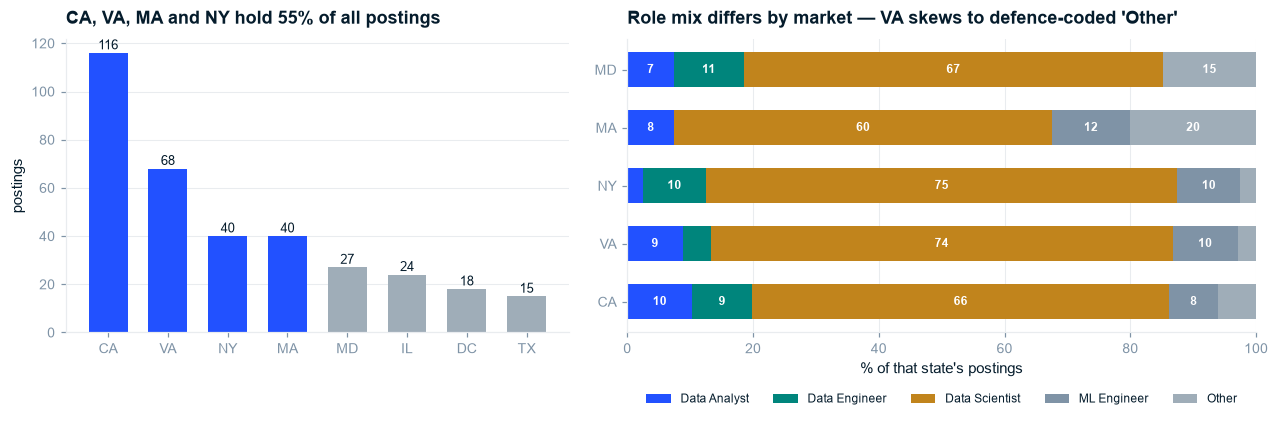


  So What:  postings concentrate hard (HHI = 0.105) and the mix is not uniform across markets
            (chi2 = 25.9, p = 0.055, Cramer's V = 0.149).
  Implication: a national 'DS market' average masks five different local markets. Any
            benchmark must be cut by state. Base: postings_dedup (492).


In [10]:
geo = dedup[~dedup.state_unspecified].job_state.value_counts()
top_states = geo.head(8)
hhi = ((geo / geo.sum()) ** 2).sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.25]})
cols = [BLUE if i < 4 else GREY for i in range(len(top_states))]
ax1.bar(top_states.index, top_states.values, color=cols, width=0.65)
for i, v in enumerate(top_states.values):
    ax1.text(i, v + 1.5, str(v), ha="center", fontsize=8.5, color=NAVY)
ax1.set_ylabel("postings")
ax1.set_title(f"CA, VA, MA and NY hold {100*top_states.head(4).sum()/geo.sum():.0f}% of all postings")
ax1.grid(axis="x", visible=False)

mix = (pd.crosstab(dedup.loc[dedup.job_state.isin(top_states.index[:5]), "job_state"],
                   dedup.loc[dedup.job_state.isin(top_states.index[:5]), "role_family"],
                   normalize="index") * 100).reindex(top_states.index[:5])
bottom = np.zeros(len(mix))
for j, rfam in enumerate(mix.columns):
    ax2.barh(mix.index, mix[rfam], left=bottom, color=CATEGORICAL[j % 5], height=0.6, label=rfam)
    for i, (v, b) in enumerate(zip(mix[rfam], bottom)):
        if v > 7:
            ax2.text(b + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                     color="white", fontweight="bold")
    bottom += mix[rfam].values
ax2.set_xlabel("% of that state's postings"); ax2.set_xlim(0, 100)
ax2.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=8)
ax2.set_title("Role mix differs by market — VA skews to defence-coded 'Other'")
ax2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

chi2, pchi, _, _ = stats.chi2_contingency(
    pd.crosstab(dedup.loc[dedup.job_state.isin(top_states.index[:5]), "job_state"],
                dedup.loc[dedup.job_state.isin(top_states.index[:5]), "role_family"]))
n_c = len(dedup[dedup.job_state.isin(top_states.index[:5])])
cramer = np.sqrt(chi2 / (n_c * (min(5, 5) - 1)))
so_what(f"""So What:  postings concentrate hard (HHI = {hhi:.3f}) and the mix is not uniform across markets
          (chi2 = {chi2:.1f}, p = {pchi:.3f}, Cramer's V = {cramer:.3f}).
Implication: a national 'DS market' average masks five different local markets. Any
          benchmark must be cut by state. Base: postings_dedup (492).""")

### Exhibit 7 — Tableau appears in 51% of analyst postings and 0% of ML-engineer postings

This is the strongest structure in the file, and the contrast with Exhibit 4 is the point: the same
data that says *nothing* about salary says a great deal about roles.

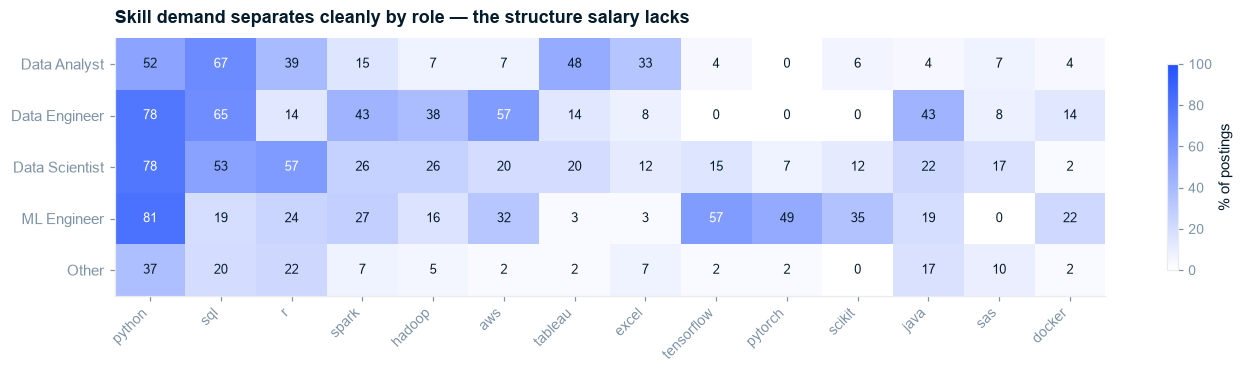


  So What:  Tableau runs 48% (Analyst) -> 3% (ML Engineer); Spark runs the other way
            (15% -> 43% for Data Engineer). These are large, monotone, interpretable.
  Implication: the file supports role-spec and skills-taxonomy work even though it cannot
            support pay benchmarking. Base: postings_dedup (492).


In [11]:
SHOW = ["python", "sql", "r", "spark", "hadoop", "aws", "tableau", "excel",
        "tensorflow", "pytorch", "scikit", "java", "sas", "docker"]
heat = pd.DataFrame({s: dedup.groupby("role_family")[f"skill_{s}"].mean() * 100 for s in SHOW})
heat = heat.reindex(["Data Analyst", "Data Engineer", "Data Scientist", "ML Engineer",
                     "Other"]).astype(float)

fig, ax = plt.subplots(figsize=(12.5, 3.5))
im = ax.imshow(heat.values, cmap=mpl.colors.LinearSegmentedColormap.from_list("b", ["#FFFFFF", BLUE]),
               aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(SHOW))); ax.set_xticklabels(SHOW, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index, fontsize=9.5)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 55 else NAVY)
ax.set_title("Skill demand separates cleanly by role — the structure salary lacks")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="% of postings")
plt.tight_layout(); plt.show()

tab = dedup.groupby("role_family").skill_tableau.mean() * 100
so_what(f"""So What:  Tableau runs {tab['Data Analyst']:.0f}% (Analyst) -> {tab['ML Engineer']:.0f}% (ML Engineer); Spark runs the other way
          ({dedup.groupby('role_family').skill_spark.mean()['Data Analyst']*100:.0f}% -> {dedup.groupby('role_family').skill_spark.mean()['Data Engineer']*100:.0f}% for Data Engineer). These are large, monotone, interpretable.
Implication: the file supports role-spec and skills-taxonomy work even though it cannot
          support pay benchmarking. Base: postings_dedup (492).""")

### Exhibit 8 — A PhD is demanded by half of ML-engineer postings and almost no analyst postings

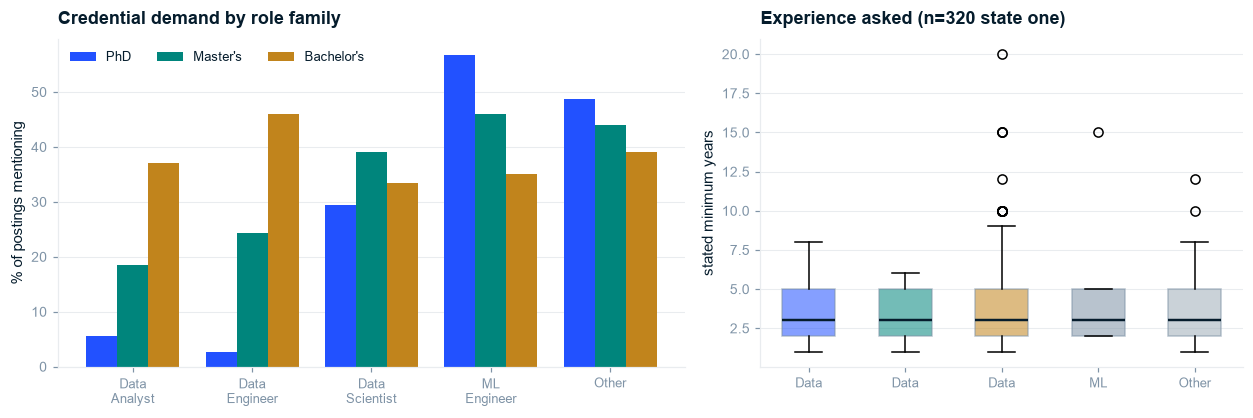


  So What:  a PhD is named in 57% of ML Engineer postings versus 6% of Analyst
            postings, while median stated experience is 3 years across the board.
  Implication: the ML Engineer entry gate is a credential, not experience. That is a
            hiring-design and access-equity finding, revisited in the fairness audit
            at Stage 6. Base: postings_dedup (492).


In [12]:
cred = dedup.groupby("role_family")[DEG_COLS].mean() * 100
cred = cred.reindex(["Data Analyst", "Data Engineer", "Data Scientist", "ML Engineer",
                     "Other"]).astype(float)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(cred)); w = 0.26
for j, (col, lab) in enumerate(zip(DEG_COLS, ["PhD", "Master's", "Bachelor's"])):
    ax1.bar(x + (j - 1) * w, cred[col], width=w, color=CATEGORICAL[j], label=lab)
ax1.set_xticks(x); ax1.set_xticklabels([i.replace(" ", "\n") for i in cred.index], fontsize=8.5)
ax1.set_ylabel("% of postings mentioning"); ax1.legend(ncol=3, fontsize=8.5)
ax1.set_title("Credential demand by role family")
ax1.grid(axis="x", visible=False)

ye = dedup.dropna(subset=["years_experience_min"])
bp = ax2.boxplot([ye[ye.role_family == r].years_experience_min.values for r in cred.index],
                 patch_artist=True, widths=0.55, medianprops={"color": NAVY, "lw": 1.6})
for patch, c in zip(bp["boxes"], CATEGORICAL):
    patch.set_facecolor(c); patch.set_alpha(0.55); patch.set_edgecolor(SLATE)
ax2.set_xticks(range(1, len(cred) + 1))
ax2.set_xticklabels([i.split()[0] for i in cred.index], fontsize=8.5)
ax2.set_ylabel("stated minimum years")
ax2.set_title(f"Experience asked (n={len(ye)} state one)")
ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

so_what(f"""So What:  a PhD is named in {cred.loc['ML Engineer','degree_phd']:.0f}% of ML Engineer postings versus {cred.loc['Data Analyst','degree_phd']:.0f}% of Analyst
          postings, while median stated experience is {ye.years_experience_min.median():.0f} years across the board.
Implication: the ML Engineer entry gate is a credential, not experience. That is a
          hiring-design and access-equity finding, revisited in the fairness audit
          at Stage 6. Base: postings_dedup (492).""")

### Exhibit 9 — Company composition, and the one company attribute that is genuinely populated

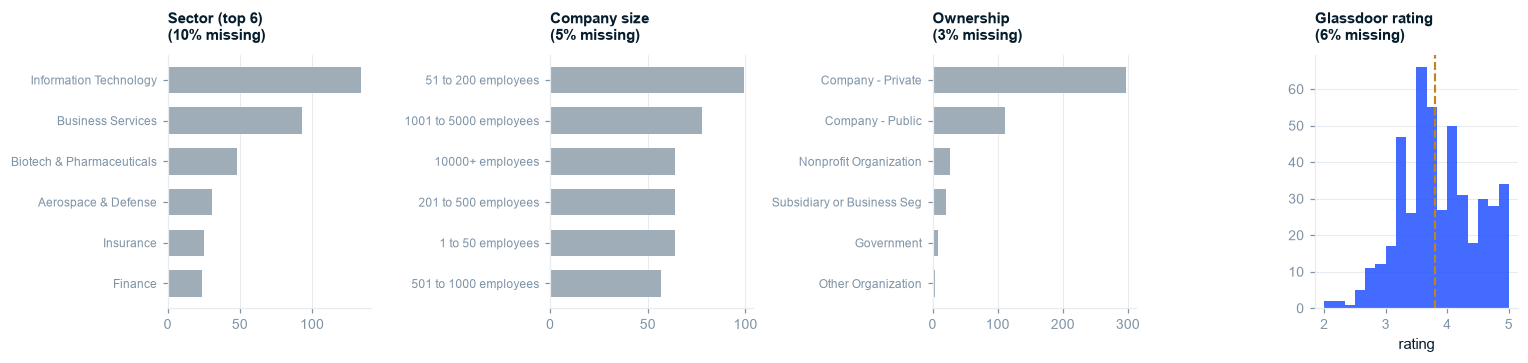


  So What:  the corpus is IT/Business-Services dominated, skews to smaller private employers,
            and Rating is the best-populated company attribute (94% present, median
            3.8, SD 0.62).
  Implication: Rating is the only company attribute complete enough to model on - which is
            why it becomes the secondary target at Stage 5b. Base: postings_dedup (492).


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, col, title in zip(axes, ["Sector", "Size", "Type of ownership"],
                          ["Sector (top 6)", "Company size", "Ownership"]):
    vc = dedup[col].value_counts().head(6)[::-1]
    ax.barh(range(len(vc)), vc.values, color=GREY, height=0.65)
    ax.set_yticks(range(len(vc)))
    ax.set_yticklabels([str(i)[:26] for i in vc.index], fontsize=8)
    ax.set_title(f"{title}\n({100*dedup[col].isna().mean():.0f}% missing)", fontsize=10)
    ax.grid(axis="y", visible=False)

axes[3].hist(dedup.Rating.dropna(), bins=18, color=BLUE, alpha=0.85)
axes[3].axvline(dedup.Rating.median(), color=AMBER, ls="--", lw=1.4)
axes[3].set_title(f"Glassdoor rating\n({100*dedup.Rating.isna().mean():.0f}% missing)", fontsize=10)
axes[3].set_xlabel("rating"); axes[3].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

so_what(f"""So What:  the corpus is IT/Business-Services dominated, skews to smaller private employers,
          and Rating is the best-populated company attribute ({100*dedup.Rating.notna().mean():.0f}% present, median
          {dedup.Rating.median():.1f}, SD {dedup.Rating.std():.2f}).
Implication: Rating is the only company attribute complete enough to model on - which is
          why it becomes the secondary target at Stage 5b. Base: postings_dedup (492).""")

---

## 3.5 Branch D — the correlation structure, and what it says about modelling

### Exhibit 10 — Salary correlates with nothing; the other numerics behave normally

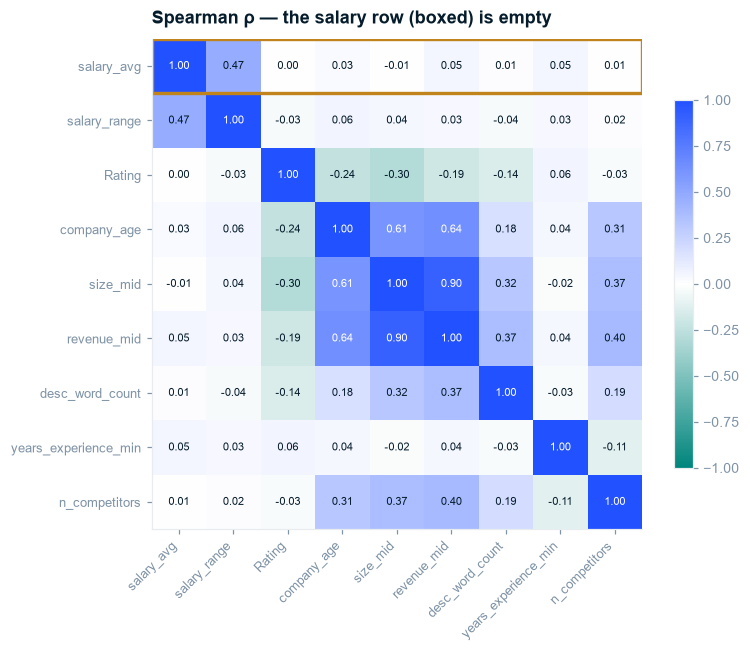


  So What:  the strongest absolute correlation anywhere in the salary row is 0.475
            (salary_range). Every other pair behaves as expected - size_mid and
            revenue_mid correlate 0.90, confirming the numeric encodings work.
  Implication: the emptiness is specific to salary, not a defect in the feature engineering.
            Base: postings_dedup (492).


In [14]:
numcols = ["salary_avg", "salary_range", "Rating", "company_age", "size_mid",
           "revenue_mid", "desc_word_count", "years_experience_min", "n_competitors"]
corr = dedup[numcols].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.4, 6))
cmap = mpl.colors.LinearSegmentedColormap.from_list("d", [TEAL, "#FFFFFF", BLUE])
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(numcols))); ax.set_xticklabels(numcols, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(len(numcols))); ax.set_yticklabels(numcols, fontsize=8.5)
for i in range(len(numcols)):
    for j in range(len(numcols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.55 else NAVY)
ax.add_patch(plt.Rectangle((-0.5, -0.5), len(numcols), 1, fill=False, edgecolor=AMBER, lw=2.2))
ax.set_title("Spearman ρ — the salary row (boxed) is empty")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout(); plt.show()

sal_corr = corr.loc["salary_avg"].drop("salary_avg").abs()
so_what(f"""So What:  the strongest absolute correlation anywhere in the salary row is {sal_corr.max():.3f}
          ({sal_corr.idxmax()}). Every other pair behaves as expected - size_mid and
          revenue_mid correlate {corr.loc['size_mid','revenue_mid']:.2f}, confirming the numeric encodings work.
Implication: the emptiness is specific to salary, not a defect in the feature engineering.
          Base: postings_dedup (492).""")

---

## 3.6 Ghost deck — revised after EDA

| # | Stage 0 anticipated | After EDA |
|---|---|---|
| EX 1 | contiguous blocks | **Confirmed** — 30/30 bands, density 1.000 |
| EX 2 | repeated postings disagree | **Confirmed, stronger** — 149/151, max $179K spread |
| EX 3 | *(not anticipated)* | **NEW — promoted to a key exhibit.** The within-batch control (Rating η²=0.02 vs salary η²=1.00) is what closes off the "file was just sorted" objection. It was not in the Stage 0 ghost deck and is now essential. |
| EX 4 | no attribute predicts salary | **Confirmed** — max η² = 0.048, seniority −$0.5K |
| EX 5–9 | market structure | **Confirmed and strengthened** — the skill×role heatmap is the natural hero for the "what it *can* do" half |
| EX 10 | *(was: leakage demo)* | **Demoted.** Leakage was expected to inflate salary R²; it does not, because duplicates carry different labels. Replaced by the correlation matrix; the leakage number moves to the appendix as a methodological note. |

**Governing Thought (draft → refined):** unchanged in direction, sharpened in evidence —
*`Salary Estimate` is a search-query artifact; comp benchmarking on this source must be stopped, not
caveated, while the role-and-skill structure is sound and answers the role-design half of the
question.*

---

## Stage 3 — Gate Checklist

- [x] **Automated profiling reviewed** — replaced with a sentinel-aware manual panel, with the reason
      stated (`ydata-profiling` would report 0% missing on this file)
- [x] **Every Stage 0 hypothesis has a corresponding analysis** — branches A, B, C, D all covered
- [x] **Key distributions and relationships visualised and annotated**
- [x] **All chart titles are Action Titles** — each states the insight, not the content
- [x] **Every finding has a documented "So What" and "Implication"**
- [x] **Ghost deck updated** — one exhibit promoted (the control), one demoted (leakage)
- [x] **Data issues logged** — none new; no loop back to Stage 2 required this pass
- [x] **Preliminary findings documented**

**Next:** `04_forensic.ipynb` — branch A and B tested formally, with a permutation test, effect sizes,
minimum detectable effects, and FDR correction.